**Stellar Stream Tutorial | Probe Combination for Dark Matter Physics in the Era of Large Surveys**

This tutorial will provide an overview of the following tasks:

Generating an unperturbed stream.
Applying a single subhalo impact.
Generating many CDM stream realizations with direct integration (somewhat slow).
Generating many CDM stream realizations with linear perturbation theory (cost: upfront compute)
Experimental: Optimizing the subhalo impact to roughly match observations. 




We start by importing the necessary libraries 

1. Astropy: We import 'units' which handles defining, converting between, and performing arithmetic with physical quantities, such as meters, seconds, Hz, etc. It also handles logarithmic units such as magnitude and decibel.
2. JAX: Open-source python framework designed for high performing numerical computing and machine learning frameworks. (We can think of it as an upgrade from numpy) The three main pillar of JAX are jax.grad which is the automatic differentiation

In [5]:
from astropy import units as u
from streamsculptor.main import usys
import jax.numpy as jnp
from astropy.coordinates import SkyCoord, Galactocentric

import matplotlib.pyplot as plt
import jax
jax.config.update("jax_enable_x64", True)

from streamsculptor import potential
from streamsculptor import JaxCoords as jc #provides cartesian to ICRS coordinte conversion
from streamsculptor import usys
from streamsculptor import gen_stream_Chen25 #provide the Chen25 stream generation function


import  diffrax #supplies the ODE solvers used to integrate orbits and generate streams
import matplotlib as mpl
import streamsculptor as ssc #provide the Chen25 stream generation function (used for unperturbed stream), 
                             #function imported directly for the perturbed streams calc later

from astropy.table import Table #reads the Gaia member data from an ECSV table
import numpy as np
import interpax  #interpolates the modelled stream'sphase-space coordinates
import equinox as eqx  #provides jax compatible utilities including jit
import tqdm #displays progress bars for longer loops


In [2]:
@jax.jit
def icrs_to_gd1(ra_rad, dec_rad):
    """
    Differentiable ra, dec --> gd1 phi1, phi2 (Koposov+2010 rotation matrix). 
    ra_rad, dec_rad in radians.
    """
    """
    Koposov+2010 rotation matrix converts from 3D ICRS to the GD-1 coordinates frame
    """
    
    R = jnp.array(
        [
            [-0.4776303088, -0.1738432154, 0.8611897727],
            [0.510844589, -0.8524449229, 0.111245042],
            [0.7147776536, 0.4930681392, 0.4959603976],
        ]
    )
                                                              #converts each (ra,dec) pair into a unit cartesian direction vector
    icrs_vec = jnp.vstack([jnp.cos(ra_rad)*jnp.cos(dec_rad),  #x-component
                           jnp.sin(ra_rad)*jnp.cos(dec_rad),  #y-component
                           jnp.sin(dec_rad)]).T               #z-component

    stream_frame_vec = jnp.einsum('ij,kj->ki', R, icrs_vec)   #appies R to every vector, producing coordinates in the GD-1 oriented frame 

    phi1 = jnp.arctan2(stream_frame_vec[:,1], stream_frame_vec[:,0])*180/jnp.pi #calculates the stream phase longitude with acrtan(y,x) and converts radians to degrees
    phi2 = jnp.arcsin(stream_frame_vec[:,2])*180/jnp.pi #calculates stream-frame lattitude with arcsin(z) and converts radians to degrees

    return phi1, phi2

@jax.jit
def get_phi12_from_stream(stream):
    """Differentiable helper: simulated stream --> phi1, phi2."""
    ra_s, dec_s, dist_ = jax.vmap(jc.simcart_to_icrs)(stream[:,:3])
    phi1_model, phi2_model = icrs_to_gd1(ra_s*jnp.pi/180, dec_s*jnp.pi/180)
    return phi1_model, phi2_model

In [6]:
"""
from astropy.table import Table

dat = "gd1_members_slim.ecsv"


tab = Table.read(dat, format="ascii.ecsv")
gd1 = tab[tab["allstream_mle"] >= 0.75]              # keep >75% membership
ra_rad  = jnp.deg2rad(np.asarray(gd1["ra"]))
dec_rad = jnp.deg2rad(np.asarray(gd1["dec"]))
phi1_data, phi2_data = icrs_to_gd1(ra_rad, dec_rad)
print(len(gd1), "GD-1 members")
"""

'\nfrom astropy.table import Table\n\ndat = "gd1_members_slim.ecsv"\n\n\ntab = Table.read(dat, format="ascii.ecsv")\ngd1 = tab[tab["allstream_mle"] >= 0.75]              # keep >75% membership\nra_rad  = jnp.deg2rad(np.asarray(gd1["ra"]))\ndec_rad = jnp.deg2rad(np.asarray(gd1["dec"]))\nphi1_data, phi2_data = icrs_to_gd1(ra_rad, dec_rad)\nprint(len(gd1), "GD-1 members")\n'

# Generating a smooth GD-1 model simulation stream

Estimated progenitor location today `[kpc, kpc, kpc, kpc/Myr, kpc/Myr, kpc/Myr]`
(from `data/GD1_prog/GD1_progenitor.npy` in the streamsculptor repo). 


In [8]:
prog_wtoday = jnp.array([-11.88431447,   1.61212652,   7.14988315,  -0.09253346, -0.22701121,  -0.10732978]) #location from GD1_progenitor.npy

**1. Setting up the Galaxy and progenitor's past state**

This returns a single six-compnent state for the progenitor t_age years ago

In [174]:
## Creates the Milky Way gravitational potential
pot = potential.GalaMilkyWayPotential(units=usys)

## Age of the stream [Myr] (how far back the simulation starts)
t_age = 4_000.0

## Past time at which it dissolved [Myr]  
t_dissolve = -300.0

## Past IC (unperturbed backward integration in the base potential)
#integrate_orbit starts from the progenito's present day state and integrates backwards to -t_age in the Milky Way potential
IC = pot.integrate_orbit(w0=prog_wtoday, t0=0.0, t1=-t_age, ts=jnp.array([-t_age])).ys[0]
IC



Array([ 18.15797218, -12.19372334,  -2.56887346,   0.05361122,
         0.12079123,  -0.11268214], dtype=float64)

**2. Generate the model stream**

Passing IC into the Chen+25 generator to create the leading and trailing stream particles. IC is the progenitor's starting state here for the simulation. Here we use the generator ssc.gen_stream_Chen25(...) which is defined in streamhelpers.py, which uses the Milky Way potential, the particles release times, progenitor's starting state and mass of the progenitor along with the rando key and vmap method to generate the leading and trailing arms.

vmap here tells the generator to use its vectorized path for generating and integrating the released particles which is defined in streamhelper.py notebook. 

In [175]:
## Stripping times. ts[-1] is always the final integration time for gen_stream simulations
N_tail = 1_500
ts = jnp.hstack([jnp.linspace(-t_age, t_dissolve, N_tail), jnp.array([0.0])]) #Set of particle release times ending at todat (0,0)

## Generate the unperturbed Chen+25 stream [l: lead, t: trail]   
l, t = ssc.gen_stream_Chen25(pot_base=pot, ts=ts, prog_w0=IC, Msat=1e4,
                             key=jax.random.PRNGKey(532), method="vmap",           
                             solver=diffrax.Dopri8(), atol=1e-7, rtol=1e-7, dtmin=0.1)
stream = jnp.vstack([l, t])

**3. Convert and plot the model**

We get a scatter plot for the modelled particles in the GD-1 coordinates. 

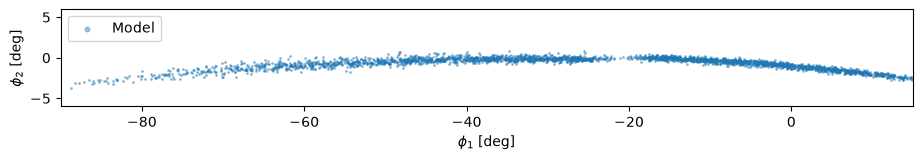

In [176]:
phi1_model, phi2_model = get_phi12_from_stream(stream)  #converts the model particles to GD-1 coordinates


fig, ax = plt.subplots(figsize=(11, 3.2))
ax.scatter(phi1_model, phi2_model, s=1.2, color="tab:blue", alpha=0.4, label="Model", rasterized=True)
#ax.scatter(phi1_data, phi2_data, s=5, zorder=-5,color="k", label="Gaia DR3 members") #plot to overlay the gaia data using the phi1data and phi2data
ax.set_xlim(-90, 15); ax.set_ylim(-6, 6)
ax.set_xlabel(r"$\phi_1$ [deg]"); ax.set_ylabel(r"$\phi_2$ [deg]")
ax.legend(loc="upper left", markerscale=3); ax.set_aspect("equal")
plt.show()



**4. Reorder the particles into GD-1 coordinates**

Interpolator estimates values between data points we already have. Helps estimate the position and velocity at a phi1 value from nearby simulated particles.

**Not clear**

In [12]:
order = jnp.argsort(phi1_model)   #Reorders particles in their GD-1 longitude
splines = [interpax.Interpolator1D(x=phi1_model[order], f=stream[order, i], method="cubic2")
           for i in range(6)]

@eqx.filter_jit
def eval_mean(phi1_0):
    "differentiable mean phase-space coordinate of the smooth stream at phi1_0"
    return jnp.array([splines[i](phi1_0) for i in range(6)])

sigma_sub = (180 * u.km/u.s).to(u.kpc/u.Myr).value    # subhalo velocity scale




**5.**

In [13]:
def get_impact_params(p):     #finds the stream at phi1 and traces it back to impact time
    "impact params dict -> SubhaloLinePotential (single subhalo on a line)"
    W0 = pot.integrate_orbit(w0=eval_mean(p["phi1_0"]), t0=0.0, t1=p["t_impact"],
                             ts=p["t_impact"][None], solver=diffrax.Dopri8(),
                             atol=1e-7, rtol=1e-7, dtmin=0.1).ys[0]
    T = W0[3:] / jnp.linalg.norm(W0[3:])
    B = jnp.cross(W0[:3], W0[3:]); B = B / jnp.linalg.norm(B)
    Nn = jnp.cross(B, T)
    b_hat   = Nn*jnp.cos(p["psi"]) + B*jnp.sin(p["psi"])   # impact offset direction
    perp    = -Nn*jnp.sin(p["psi"]) + B*jnp.cos(p["psi"])  # in-plane perpendicular
    X = W0[:3] + p["b"] * b_hat
    w = p["wspeed"] * (p["wpar_frac"]*T + jnp.sqrt(jnp.maximum(1 - p["wpar_frac"]**2, 0.))*perp)
    V = W0[3:] + w
    return X, V

#returns subhalo position and velocity


def build_subhalo(p):
    """
    Subhalo params dict -> SubhaloLinePotential (single subhalo on a line)
    """
    X, V = get_impact_params(p)
    return potential.SubhaloLinePotential(
        m=jnp.array([10**p["log10m"]]), a=jnp.array([p["a"]]),
        subhalo_x0=X[None], subhalo_v=V[None], subhalo_t0=p["t_impact"][None],
        t_window=jnp.array([250.0]), units=usys)

KEY   = jax.random.PRNGKey(0)
SOLVE = dict(solver=diffrax.Dopri5(), rtol=1e-6, atol=1e-6, dtmin=0.5)

@eqx.filter_jit
def perturbed_stream(p, pot_SH):
    "Backward-integrate the progenitor WITH the impact (so it always lands at today's observed"
    "position), then forward-generate the stream (Chen+25, vmap). This anchors the present-day"
    "progenitor: the impact perturbs the stream, not where the progenitor ends up."
    #SH = build_subhalo(p)
    pot_tot = potential.Potential_Combine(potential_list=[pot, pot_SH], units=usys)
    IC_pert = pot_tot.integrate_orbit(w0=prog_wtoday, t0=0.0, t1=-t_age, ts=jnp.array([-t_age]),
                                      solver=diffrax.Dopri8(), rtol=1e-7, atol=1e-7, dtmin=0.1).ys[0]
    l, t = gen_stream_Chen25(pot, ts, IC_pert, Msat=1e4, key=KEY, method="vmap",
                             pot_pert=pot_SH, **SOLVE)
    return jnp.vstack([l, t])

**6.**

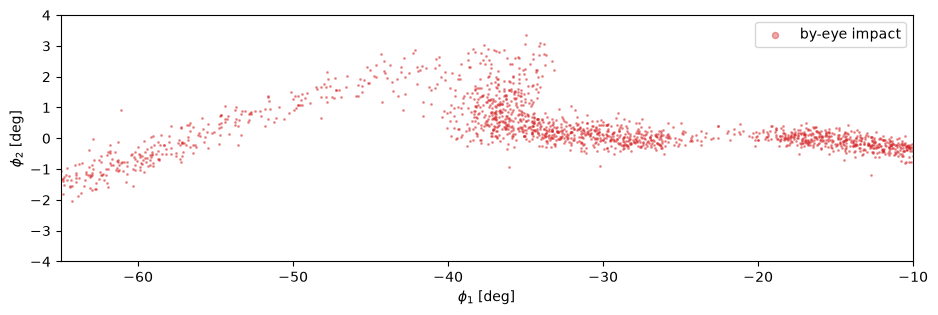

In [15]:
p_eye = dict(phi1_0=jnp.array(-50.0), t_impact=jnp.array(-180.0), #-200
             b=jnp.array(0.2), psi=jnp.array(jnp.deg2rad(210.)),
             wspeed=jnp.array(.4*sigma_sub), wpar_frac=jnp.array(.7), #.4, .7
             log10m=jnp.array(7.2), a=jnp.array(.1))

sub_pot = build_subhalo(p_eye)
stream_eye = perturbed_stream(p_eye, sub_pot)
p1_eye, p2_eye = get_phi12_from_stream(stream_eye)

fig, ax = plt.subplots(figsize=(11, 3.2))
#ax.scatter(phi1_data, phi2_data, s=5, color="k", label="data")
ax.scatter(p1_eye, p2_eye, s=1.2, color="tab:red", alpha=0.4, label="by-eye impact", rasterized=True)
ax.set_xlim(-65, -10); ax.set_ylim(-4, 4)
ax.set_xlabel(r"$\phi_1$ [deg]"); ax.set_ylabel(r"$\phi_2$ [deg]"); ax.legend(markerscale=4)
plt.show()


/var/folders/h3/fz1rp8057wj6r12l46wrjwbr0000gn/T/ipykernel_36717/3815835521.py:21: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.set_xlabel(r"$\phi_1$ [deg]"); ax.set_ylabel(r"$\phi_2$ [deg]"); ax.legend(markerscale=4)


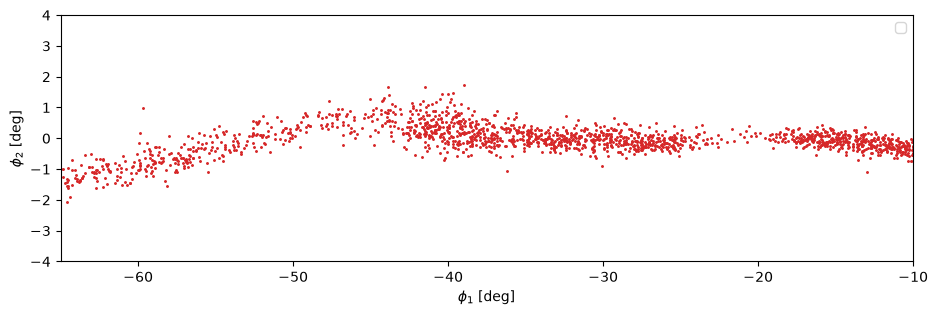

In [18]:
from streamsculptor.tnfw_analytic import TNFWSubhaloLinePotential

X,V = get_impact_params(p_eye)

pot_line_tnfw = TNFWSubhaloLinePotential.from_infall(
    m_infall=jnp.array([2e7]), c_infall=jnp.array([120.0]), z_infall=jnp.array([10.0]), f_bound=jnp.array([.3]),
    subhalo_x0=X[None], subhalo_v=V[None], subhalo_t0=p_eye['t_impact'][None],
    t_window=250.0,
    )

stream_tnfw = perturbed_stream(p_eye,pot_line_tnfw)

p1_tnfw, p2_tnfw = get_phi12_from_stream(stream_tnfw)


fig, ax = plt.subplots(figsize=(11, 3.2))
#ax.scatter(phi1_data, phi2_data, s=5, color="k", label="data")
ax.scatter(p1_tnfw, p2_tnfw, s=1.2, color="tab:red", alpha=1.0, rasterized=True)
ax.set_xlim(-65, -10)
ax.set_ylim(-4, 4)
ax.set_xlabel(r"$\phi_1$ [deg]"); ax.set_ylabel(r"$\phi_2$ [deg]"); ax.legend(markerscale=4)
plt.show()


In [19]:
# cycle through a few z_infall
z_infall_high = 10.0
z_infall_low = 0.5
z_infall_trial = jnp.logspace(jnp.log10(z_infall_high),jnp.log10(z_infall_low),4)
p1_tnfw_arr = np.zeros((len(p1_tnfw),len(z_infall_trial)))
p2_tnfw_arr = np.zeros((len(p1_tnfw),len(z_infall_trial)))
for i in tqdm.tqdm(range(len(z_infall_trial))):
    z_infall = z_infall_trial[i]
    
    pot_line_tnfw = TNFWSubhaloLinePotential.from_infall(
                m_infall=jnp.array([3e7]), c_infall=jnp.array([120.0]), z_infall=z_infall, f_bound=jnp.array([.8]),
                subhalo_x0=X[None], subhalo_v=V[None], subhalo_t0=p_eye['t_impact'][None],
                t_window=250.0,
               
                )

    stream_tnfw = perturbed_stream(p_eye,pot_line_tnfw)

    p1_tnfw, p2_tnfw = get_phi12_from_stream(stream_tnfw)
    p1_tnfw_arr[:,i] = p1_tnfw
    p2_tnfw_arr[:,i] = p2_tnfw




100%|████████████████████████████████████████████| 4/4 [00:01<00:00,  2.35it/s]


In [20]:
z_infall_trial

Array([10.        ,  3.6840315 ,  1.35720881,  0.5       ], dtype=float64)

findfont: Failed to find font weight medium for DejaVu Sans, now using 400.
findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


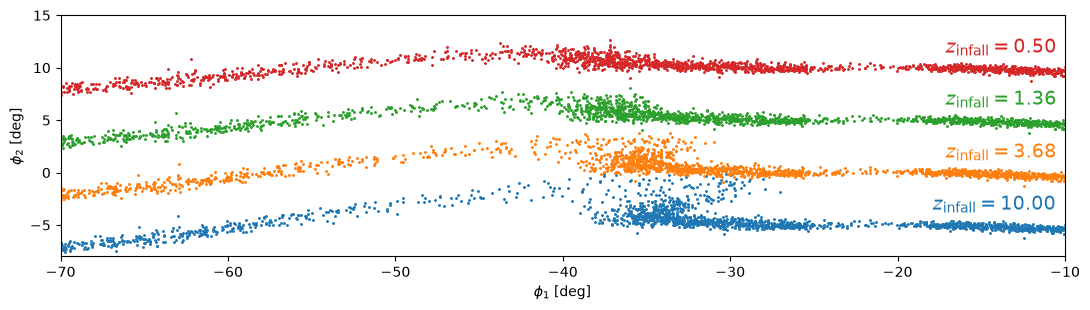

In [21]:
fig, ax = plt.subplots(figsize=(11, 3.2))

for i in range(len(z_infall_trial)):
  y_stream = p2_tnfw_arr[:, i] - 5 + i * 5
  sc = ax.scatter(p1_tnfw_arr[:, i], y_stream, s=1.2, alpha=1.0, rasterized=True)

  # Find the rightmost point in the stream to anchor the text
  idx_right = np.nanargmax(p1_tnfw_arr[:, i])
  x_pos = -10.5
  y_pos = y_stream[idx_right] + 4.5

  ax.text(
      x_pos,
      y_pos + 0.9,
      rf"$z_{{\rm infall}} = {z_infall_trial[i]:.2f}$",
      color=sc.get_facecolor()[0],
      fontsize=14,
      ha="right",
      va="bottom",
      fontweight="medium",
  )

ax.set_xlim(-70, -10)
ax.set_ylim(-8, 15)
ax.set_xlabel(r"$\phi_1$ [deg]")
ax.set_ylabel(r"$\phi_2$ [deg]")
plt.tight_layout()
plt.show()

In [22]:
from streamsculptor.GenerateImpactParams import ImpactGenerator

ImpactGen = ImpactGenerator(pot=pot,
                            tobs=0.0,
                            stream=stream,
                            stream_phi1=phi1_model,
                            phi1_bounds=[-80.,20.],
                            tImpactBounds=[-t_age,0.0],
                            phi1window=.8,
                            NumImpacts=20,
                            bImpact_bounds=[0,.1],
                            stripping_times=jnp.hstack([ts[:-1],ts[:-1]]),
                            prog_today=prog_wtoday,
                            seednum=2332)#22

ImpactDict = ImpactGen.get_subhalo_ImpactParams()
print(ImpactDict.keys())

dict_keys(['CartesianImpactParams', 'ImpactFrameParams'])


In [23]:
ImpactDict['CartesianImpactParams']

Array([[ 6.80708820e-01,  1.75325732e+01,  8.25020566e+00,
        -1.35420130e-01, -2.22508633e-01,  2.66026243e-01],
       [-1.83874934e+00, -2.07863112e+01,  4.79430146e+00,
         2.57248687e-01,  5.31240031e-02,  2.01355290e-01],
       [-1.39673398e+01,  4.78620986e-01,  1.01602506e+01,
        -2.98617730e-02,  6.99647703e-02,  4.23259315e-01],
       [ 1.03728387e+01,  1.01472564e+01, -2.26314183e+00,
        -2.67108977e-01, -2.42098236e-01,  2.44704735e-01],
       [ 2.87207273e+00,  1.40174987e+01,  2.32322399e+00,
         1.16232275e-01,  3.45588269e-01, -1.38785665e-01],
       [-1.22801101e+01,  1.14788665e+01,  1.41014107e+01,
        -8.99550924e-02,  2.24543987e-02,  9.72657574e-02],
       [ 1.10627338e+01, -8.04339004e+00, -3.83315492e+00,
         4.07017206e-03, -3.68531233e-01, -3.08458211e-01],
       [-9.39863158e+00,  8.50160970e+00,  5.74011557e+00,
         1.89381636e-01, -2.59469723e-01, -1.01611978e-01],
       [-9.40351381e+00,  6.77437554e+00,  9.475

In [24]:
ImpactDict['ImpactFrameParams']

{'bImpact': Array([0.06196671, 0.06273178, 0.0880017 , 0.01324513, 0.05267255,
        0.09817768, 0.01893633, 0.03891576, 0.0637155 , 0.0474636 ,
        0.09570626, 0.04154716, 0.0216201 , 0.07875177, 0.09996749,
        0.04145548, 0.0620432 , 0.08941731, 0.04547729, 0.06583859],      dtype=float64),
 'perp_angle': Array([2.45448055, 6.16543016, 3.83918173, 1.88101644, 5.0848122 ,
        1.40504958, 5.63211525, 4.6996889 , 4.56737002, 5.5715057 ,
        4.04919872, 0.31876962, 6.09421744, 4.38814402, 4.24236626,
        4.84347171, 2.0598215 , 1.92944766, 4.50441197, 0.07300123],      dtype=float64),
 'phi1_samples': Array([ 6.49209297e+00, -1.34093499e-02, -3.28904186e+01, -4.85756488e+01,
        -5.59102908e+00, -7.17903817e+01, -6.58072969e+01, -2.98371770e+01,
        -5.13645121e+01, -4.67050168e+01,  7.04391353e+00, -6.70228886e+01,
        -6.21514895e+01, -5.32001400e+01, -3.46635005e+01, -3.01811442e+01,
        -1.47467139e-01, -5.91764813e+01, -4.57439485e+01, -7.05568

In [25]:
@jax.jit
def gen_perturbed_stream(m, rs):
    """
    Generate a perturbed stream given 
    an array of subhalo masses and scale radii. 
    Outputs N x 6 array [kpc, kpc/Myr]
    """
    pot_SH = potential.SubhaloLinePotential(m=m,
                                            a=rs,
                                            subhalo_x0=ImpactDict['CartesianImpactParams'][:,:3],
                                            subhalo_v=ImpactDict['CartesianImpactParams'][:,3:],
                                            subhalo_t0=ImpactDict['ImpactFrameParams']['tImpact'],
                                            t_window=jnp.array([200.0]),
                                            units=usys)

    pot_total = potential.Potential_Combine([pot, pot_SH], units=usys)

    # Do NOT fix the prog: perturbed past IC via backward integration in base + subhalos
    IC_pert = pot_total.integrate_orbit(w0=prog_wtoday, t0=0.0, t1=-t_age,
                                        ts=jnp.array([-t_age]), max_steps=5_000).ys[0]

    l, t = ssc.gen_stream_Chen25(pot_base=pot, pot_pert=pot_SH, prog_w0=IC_pert, ts=ts,
                                 Msat=1e4, key=jax.random.PRNGKey(532), method="vmap",
                                 max_steps=5_000, atol=1e-6, rtol=1e-6,
                                 solver=diffrax.Dopri8(), dtmin=.1)
    return jnp.vstack([l, t])

In [26]:
m = jnp.ones(20)*5e6
rs = jnp.ones(20)*.1
perturbed_stream = gen_perturbed_stream(m, rs)

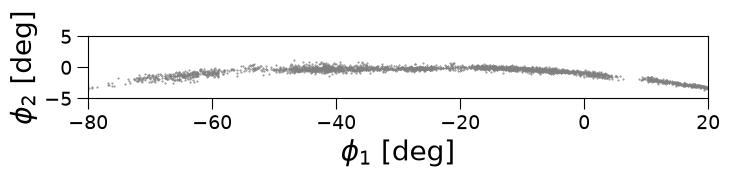

In [27]:
phi1_pert, phi2_pert = get_phi12_from_stream(perturbed_stream[:,:3])

fig, ax = plt.subplots(1,1)
fig.set_size_inches(8,8)
ax.scatter(phi1_pert, phi2_pert, s=.2, color='grey')

ax.tick_params(axis='both', which='major', labelsize=14., length=8)
ax.tick_params(axis='both', which='minor', length=3)
ax.set_ylim(-5,5)
ax.set_xlim(-80,20)
ax.set_xlabel(r'$\phi_1$ [deg]', fontsize=20)
ax.set_ylabel(r'$\phi_2$ [deg]', fontsize=20)
ax.set_aspect('equal')